In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [12]:
LOOKBACK = 30
HORIZON = 1

MODEL_PATH = "../data/models/lstm_nvda.pt"
SCALER_PATH = "../data/models/scaler_nvda.pkl"
DATA_PATH = "../data/processed/nvda_clean.csv"

In [13]:
def create_windows(values, lookback, horizon=1):
    X, y = [], []
    for i in range(len(values) - lookback - horizon + 1):
        X.append(values[i : i + lookback])
        y.append(values[i + lookback + horizon - 1])
    return np.array(X), np.array(y)

In [14]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, num_layers=1):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last_output = lstm_out[:, -1, :]
        return self.fc(last_output)

In [15]:
# Carregar modelo
model = LSTMModel()
model.load_state_dict(torch.load(MODEL_PATH))
model.eval()

# Carregar scaler
scaler = joblib.load(SCALER_PATH)

print("Modelo e scaler carregados com sucesso.")

Modelo e scaler carregados com sucesso.


/Users/marianna/Downloads/drive-download-20260104T194022Z-3-001/.venv/lib/python3.11/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [16]:
df = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True)

VAL_END = "2023-12-31"
test = df.loc[VAL_END:].iloc[1:]

print("Test shape:", test.shape)
test.head()

Test shape: (493, 1)


,close
Date,
2024-01-03,47.542511
2024-01-04,47.971279
2024-01-05,49.069656
2024-01-08,52.223900
2024-01-09,53.110413


In [17]:
scaler.transform(test[["close"]])



array([[ 4.93515657],
       [ 4.99401368],
       [ 5.14478818],
       [ 5.57777193],
       [ 5.69946375],
       [ 5.86546793],
       [ 5.93022337],
       [ 5.91485755],
       [ 6.14424626],
       [ 6.09910968],
       [ 6.24371147],
       [ 6.57078238],
       [ 6.59314409],
       [ 6.62318976],
       [ 6.8274713 ],
       [ 6.86245546],
       [ 6.78206033],
       [ 6.97879563],
       [ 7.02118778],
       [ 6.85010845],
       [ 7.0558986 ],
       [ 7.48572687],
       [ 7.92090575],
       [ 7.76875772],
       [ 8.02613314],
       [ 7.9632979 ],
       [ 8.30518743],
       [ 8.32096379],
       [ 8.30450041],
       [ 8.5476086 ],
       [ 8.37721053],
       [ 8.37103781],
       [ 7.93736913],
       [ 7.66572545],
       [ 9.18391301],
       [ 9.22218932],
       [ 9.2599179 ],
       [ 9.20627262],
       [ 9.06386648],
       [ 9.26266075],
       [ 9.69715365],
       [10.10297282],
       [10.20326644],
       [10.57864616],
       [11.1231934 ],
       [10

In [18]:
# Normalizar dados de teste
test_scaled = scaler.transform(test[["close"]])

# Criar janelas
X_test, y_test = create_windows(test_scaled, LOOKBACK, HORIZON)

# Ajustar shape para LSTM
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Converter para tensor
X_test_t = torch.tensor(X_test, dtype=torch.float32)

print("X_test:", X_test_t.shape)
print("y_test:", y_test.shape)

X_test: torch.Size([463, 30, 1])
y_test: (463, 1)


In [19]:
with torch.no_grad():
    y_pred_scaled = model(X_test_t).numpy()

# Desnormalizar
y_pred = scaler.inverse_transform(y_pred_scaled).ravel()
y_true = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

print("Exemplo de previsão:", y_pred[:5])

Exemplo de previsão: [41.82041  41.80797  41.810707 41.74395  41.685745]


In [20]:
# Naive baseline (último valor da janela)
y_pred_naive = test["close"].values[LOOKBACK - 1 : -1]

# Média móvel
y_pred_ma = np.array([
    test["close"].values[i : i + LOOKBACK].mean()
    for i in range(len(test) - LOOKBACK)
])

In [21]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

results = {
    "Modelo": ["Naive", "Média Móvel", "LSTM"],
    "MAE": [
        mean_absolute_error(y_true, y_pred_naive),
        mean_absolute_error(y_true, y_pred_ma),
        mean_absolute_error(y_true, y_pred),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_true, y_pred_naive)),
        np.sqrt(mean_squared_error(y_true, y_pred_ma)),
        np.sqrt(mean_squared_error(y_true, y_pred)),
    ],
    "MAPE (%)": [
        mape(y_true, y_pred_naive),
        mape(y_true, y_pred_ma),
        mape(y_true, y_pred),
    ],
}

results_df = pd.DataFrame(results)
results_df

,Modelo,MAE,RMSE,MAPE (%)
0,Naive,3.014903,4.035003,2.367757
1,Média Móvel,9.335938,11.389276,7.363419
2,LSTM,93.543206,99.428967,67.427576


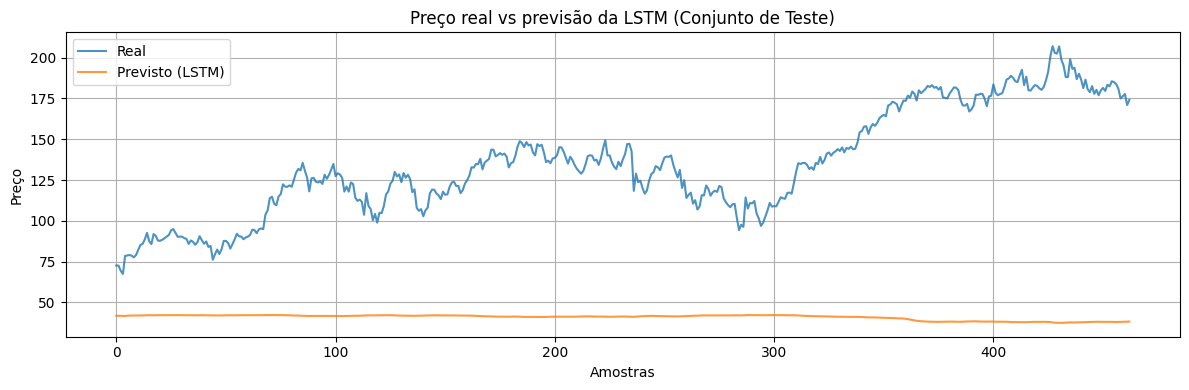

In [22]:
plt.figure(figsize=(12, 4))
plt.plot(y_true, label="Real", alpha=0.8)
plt.plot(y_pred, label="Previsto (LSTM)", alpha=0.8)
plt.title("Preço real vs previsão da LSTM (Conjunto de Teste)")
plt.xlabel("Amostras")
plt.ylabel("Preço")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

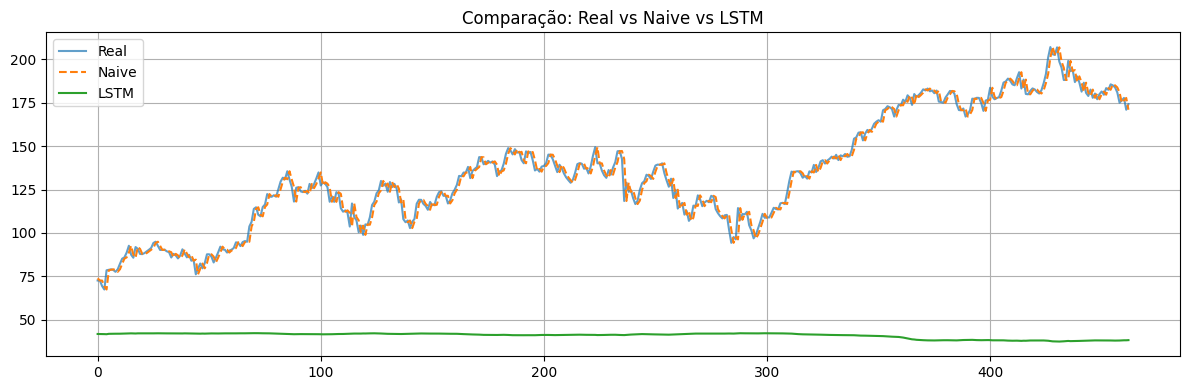

In [23]:
plt.figure(figsize=(12, 4))
plt.plot(y_true, label="Real", alpha=0.7)
plt.plot(y_pred_naive, label="Naive", linestyle="--")
plt.plot(y_pred, label="LSTM")
plt.title("Comparação: Real vs Naive vs LSTM")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()